# Implementation of StyleGAN for High-Quality Face Image Generation

### From DCGAN to StyleGAN — Generative AI Lab

**Prerequisite:** This notebook assumes you have already completed the *Face Generation using DCGAN on CelebA* lab. We build directly on that foundation.

---

## 1. Recap: Where DCGAN Left Off

In the DCGAN lab, you trained a generator that takes a single random noise vector `z` and, through a stack of transposed convolutions, produces a face image directly. This works, but has three well-known limitations:

| Limitation of DCGAN | Why it happens |
|---|---|
| **No control over generated features** | `z` is fed only once, at the input layer. There is no mechanism to influence style at specific scales (e.g. pose vs. hair color vs. skin texture separately). |
| **Entangled latent space** | Because `z` samples from a fixed prior (e.g. Gaussian) and is mapped directly to pixels, semantically meaningful directions in `z`-space are tangled together. |
| **Quality/diversity trade-off & training instability** | A single noise injection point makes it hard for the network to add fine stochastic detail (skin pores, hair strands) without affecting the overall structure. |

**StyleGAN** (Karras et al., *A Style-Based Generator Architecture for Generative Adversarial Networks*, CVPR 2019) redesigns only the **generator** to fix exactly these problems, while the discriminator stays close to a standard CNN discriminator (similar to what you already built for DCGAN).

## 2. Problem Statement

> **Build a style-based Generative Adversarial Network (StyleGAN) that synthesizes high-quality, diverse human face images from the CelebA dataset, and demonstrate explicit control over the generation process through a learned intermediate latent space, allowing coarse-to-fine style control, style mixing between two identities, and stochastic detail variation via noise injection — capabilities that a vanilla DCGAN generator cannot offer.**

### Learning Objectives
By the end of this notebook you will be able to:
1. Explain the architectural differences between a DCGAN generator and a StyleGAN generator.
2. Implement the **Mapping Network** (`z → w`) and understand why an intermediate latent space `W` disentangles style better than `Z`.
3. Implement **Adaptive Instance Normalization (AdaIN)** to inject style at every resolution of the synthesis network.
4. Implement **per-pixel noise injection** for stochastic detail.
5. Train a simplified StyleGAN on CelebA and visualize results.
6. Demonstrate the **truncation trick** and **style mixing**, two signature StyleGAN capabilities.

### A Note on Scope
The original StyleGAN is trained on 1024×1024 images using **progressive growing**, 8-layer mapping networks, and days of multi-GPU compute (FFHQ dataset). That is not feasible inside a single Colab session. This notebook implements a **faithful but compute-friendly StyleGAN** — same core ideas (mapping network, AdaIN, noise injection, style mixing, truncation trick), fixed-resolution synthesis network (64×64, easily extendable to 128×128), trained on a CelebA subset. This keeps the lab runnable in class while teaching the real architecture, not a toy simplification of the *ideas*.

## 3. Environment Setup

In [1]:
import torch
print('CUDA available:', torch.cuda.is_available())
print('GPU:', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'None — go to Runtime > Change runtime type > GPU')

CUDA available: True
GPU: Tesla T4


In [2]:
!pip install -q datasets


In [3]:
import os
import random
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as transforms
import torchvision.utils as vutils
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Using device:', device)

Using device: cuda


## 4. Dataset: CelebA (Aligned Faces)

We use the same *family* of data as the DCGAN lab — **CelebA aligned & cropped face images** — loaded through the Hugging Face `datasets` hub, which avoids the Google Drive quota errors that often break `torchvision.datasets.CelebA`.

> **Note:** the dataset repo `huggan/CelebA-faces` that many older tutorials reference has been removed from the Hub. This notebook uses **`tpremoli/CelebA-attrs-20k`** instead — an actively maintained, verified mirror of a 20k-image CelebA subset (same aligned face images; it also carries the 40 CelebA attribute columns, which we simply ignore here since StyleGAN training is unconditional). If this repo ever becomes unavailable too, swap in `tpremoli/CelebA-attrs` (the full ~203k-image version) and keep the `.select(range(NUM_IMAGES))` subsetting line below.

This is already a 20k-image subset sized for a classroom-length training run, so no extra downsampling of the dataset is needed — increase `NUM_IMAGES` (up to ~20,000) or point at the full `tpremoli/CelebA-attrs` repo if you have more time/compute.

In [4]:
from datasets import load_dataset

IMG_SIZE   = 64      # synthesis resolution (extend to 128 if you have time/compute)
NUM_IMAGES = 20000   # subset size for a class-length training run (max ~20,000 for this repo)
BATCH_SIZE = 64

print('Downloading CelebA faces (this may take a few minutes the first time)...')
hf_dataset = load_dataset('tpremoli/CelebA-attrs-20k', split='train')
NUM_IMAGES = min(NUM_IMAGES, len(hf_dataset))
hf_dataset = hf_dataset.select(range(NUM_IMAGES))
print('Loaded', len(hf_dataset), 'images')

README.md:   0%|          | 0.00/2.67k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  141MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 17.3MB            

data/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

...

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/19999 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/2451 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/2440 [00:00<?, ? examples/s]

Loaded 19999 images


In [5]:
transform = transforms.Compose([
    transforms.Resize(IMG_SIZE),
    transforms.CenterCrop(IMG_SIZE),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),  # scale to [-1, 1] to match tanh output
])

class CelebADataset(Dataset):
    def __init__(self, hf_ds, transform):
        self.hf_ds = hf_ds
        self.transform = transform
    def __len__(self):
        return len(self.hf_ds)
    def __getitem__(self, idx):
        img = self.hf_ds[idx]['image'].convert('RGB')
        return self.transform(img)

dataset = CelebADataset(hf_dataset, transform)
dataloader = DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2, drop_last=True)
print('Number of batches per epoch:', len(dataloader))

Number of batches per epoch: 312


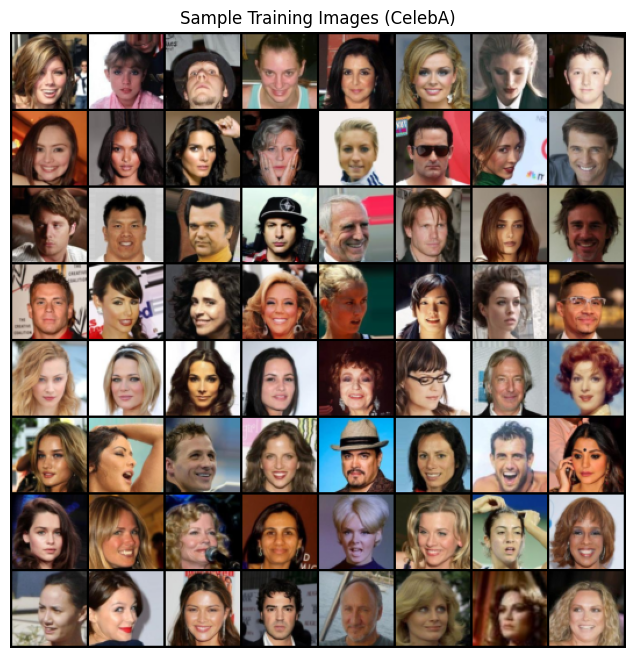

In [6]:
# Sanity check: visualize a batch of real images
real_batch = next(iter(dataloader))
plt.figure(figsize=(8, 8))
plt.axis('off')
plt.title('Sample Training Images (CelebA)')
plt.imshow(np.transpose(vutils.make_grid(real_batch[:64], padding=2, normalize=True).cpu(), (1, 2, 0)))
plt.show()

## 5. StyleGAN Architecture

The key idea: instead of feeding `z` into the generator once, StyleGAN separates *what varies* into two channels:

```
        z  (random noise, Z-space)
        |
        v
  Mapping Network  f: Z -> W   (8 fully-connected layers, here reduced for speed)
        |
        v
        w  (intermediate latent, W-space, more DISENTANGLED than Z)
        |
        +---------------------------------------------------+
        |                    injected at EVERY               |
        |                    resolution via AdaIN             |
        v                                                     v
  learned constant 4x4 --AdaIN--> conv --AdaIN--> upsample --AdaIN--> ... --> RGB image
        ^                    ^
        |                    |
   noise (B)            noise (B)   <-- per-pixel stochastic noise, independent of w
```

### 5.1 Why a Mapping Network?
If `z` is sampled from a fixed distribution (e.g. Gaussian) and features in the training data are correlated (e.g. 'long hair' mostly co-occurs with 'female'), a direct `Z -> image` mapping is forced to warp `Z`-space non-linearly to match those correlations, entangling factors of variation. The Mapping Network learns an **8-layer MLP** `f: Z -> W` so that `W` need not follow any fixed distribution — it can 'unwarp' to a space where factors of variation become more linear/disentangled and each direction in `W` more closely controls one interpretable attribute.

### 5.2 Adaptive Instance Normalization (AdaIN)
At every convolutional block, StyleGAN normalizes the feature map (removing its own mean/variance, i.e. Instance Norm) and then re-scales and re-biases it using values **learned from `w`**:

$$\text{AdaIN}(x_i, w) = y_{s,i}\,\frac{x_i - \mu(x_i)}{\sigma(x_i)} + y_{b,i}$$

where `y_s` (scale) and `y_b` (bias) are produced by small learned affine transforms of `w`, one pair per channel, per layer. This is how the *same* `w` gets to influence style at **every resolution** — early (low-res) layers control coarse style (pose, face shape), middle layers control mid-level style (facial features), late (high-res) layers control fine style (color scheme, micro-texture).

### 5.3 Stochastic Noise Injection
Independent Gaussian noise is added at each layer (scaled by a learned per-channel weight), giving the network a way to generate fine stochastic detail (hair strand placement, skin pore pattern) **without** using up `w`'s capacity — `w` handles the identity/style, and noise handles per-image randomness at fixed style.

In [7]:
class PixelNorm(nn.Module):
    """Normalizes each latent vector to unit norm — stabilizes the mapping network."""
    def forward(self, x):
        return x / torch.sqrt(torch.mean(x ** 2, dim=1, keepdim=True) + 1e-8)


class MappingNetwork(nn.Module):
    """f: Z -> W.  Original paper uses 8 layers; we use 6 for a faster classroom run."""
    def __init__(self, z_dim=256, w_dim=256, n_layers=6):
        super().__init__()
        layers = [PixelNorm()]
        in_dim = z_dim
        for _ in range(n_layers):
            layers.append(nn.Linear(in_dim, w_dim))
            layers.append(nn.LeakyReLU(0.2, inplace=True))
            in_dim = w_dim
        self.mapping = nn.Sequential(*layers)

    def forward(self, z):
        return self.mapping(z)

In [8]:
class AdaIN(nn.Module):
    """Adaptive Instance Normalization: style (w) modulates normalized features."""
    def __init__(self, channels, w_dim):
        super().__init__()
        self.instance_norm = nn.InstanceNorm2d(channels, affine=False)
        self.style_scale = nn.Linear(w_dim, channels)
        self.style_bias = nn.Linear(w_dim, channels)
        # Initialize so the block starts close to identity-ish behaviour
        nn.init.ones_(self.style_scale.bias)
        nn.init.zeros_(self.style_bias.bias)

    def forward(self, x, w):
        x = self.instance_norm(x)
        scale = self.style_scale(w).unsqueeze(2).unsqueeze(3)
        bias = self.style_bias(w).unsqueeze(2).unsqueeze(3)
        return scale * x + bias


class NoiseInjection(nn.Module):
    """Adds per-pixel Gaussian noise scaled by a learned per-channel weight."""
    def __init__(self, channels):
        super().__init__()
        self.weight = nn.Parameter(torch.zeros(1, channels, 1, 1))

    def forward(self, x, noise=None):
        if noise is None:
            noise = torch.randn(x.size(0), 1, x.size(2), x.size(3), device=x.device)
        return x + self.weight * noise

In [9]:
class SynthesisBlock(nn.Module):
    """One resolution stage of the synthesis network: (optional upsample) -> conv -> noise -> AdaIN, twice."""
    def __init__(self, in_ch, out_ch, w_dim, upsample=True):
        super().__init__()
        self.upsample = upsample
        self.conv1 = nn.Conv2d(in_ch, out_ch, 3, padding=1)
        self.noise1 = NoiseInjection(out_ch)
        self.adain1 = AdaIN(out_ch, w_dim)
        self.conv2 = nn.Conv2d(out_ch, out_ch, 3, padding=1)
        self.noise2 = NoiseInjection(out_ch)
        self.adain2 = AdaIN(out_ch, w_dim)
        self.act = nn.LeakyReLU(0.2, inplace=True)

    def forward(self, x, w):
        if self.upsample:
            x = F.interpolate(x, scale_factor=2, mode='bilinear', align_corners=False)
        x = self.act(self.conv1(x))
        x = self.noise1(x)
        x = self.adain1(x, w)
        x = self.act(self.conv2(x))
        x = self.noise2(x)
        x = self.adain2(x, w)
        return x

In [10]:
class Generator(nn.Module):
    """
    Style-based synthesis network.
    Starts from a LEARNED CONSTANT (not from z!) at 4x4 and grows to 64x64,
    receiving style (w) at every block via AdaIN and independent noise at every block.
    """
    def __init__(self, w_dim=256, base_channels=256, img_channels=3):
        super().__init__()
        self.channels = {4: 256, 8: 256, 16: 128, 32: 64, 64: 32}
        self.resolutions = [4, 8, 16, 32, 64]

        self.starting_constant = nn.Parameter(torch.randn(1, self.channels[4], 4, 4))
        self.initial_noise = NoiseInjection(self.channels[4])
        self.initial_adain1 = AdaIN(self.channels[4], w_dim)
        self.initial_conv = nn.Conv2d(self.channels[4], self.channels[4], 3, padding=1)
        self.initial_noise2 = NoiseInjection(self.channels[4])
        self.initial_adain2 = AdaIN(self.channels[4], w_dim)
        self.act = nn.LeakyReLU(0.2, inplace=True)

        self.blocks = nn.ModuleList()
        for i in range(1, len(self.resolutions)):
            in_ch = self.channels[self.resolutions[i - 1]]
            out_ch = self.channels[self.resolutions[i]]
            self.blocks.append(SynthesisBlock(in_ch, out_ch, w_dim, upsample=True))

        self.to_rgb = nn.Conv2d(self.channels[64], img_channels, kernel_size=1)
        self.num_style_inputs = 1 + len(self.blocks)  # how many w's this net can use (for style mixing)

    def forward(self, ws):
        """
        ws: either a single [B, w_dim] tensor (same style at every layer) OR
            a list of `num_style_inputs` tensors, one per block, for STYLE MIXING.
        """
        if isinstance(ws, torch.Tensor):
            ws = [ws] * self.num_style_inputs
        assert len(ws) == self.num_style_inputs

        batch = ws[0].shape[0]
        x = self.starting_constant.expand(batch, -1, -1, -1)
        x = self.initial_noise(x)
        x = self.initial_adain1(x, ws[0])
        x = self.act(self.initial_conv(x))
        x = self.initial_noise2(x)
        x = self.initial_adain2(x, ws[0])

        for i, block in enumerate(self.blocks):
            x = block(x, ws[i + 1])

        return torch.tanh(self.to_rgb(x))

In [11]:
class Discriminator(nn.Module):
    """Plain CNN discriminator (deliberately close to your DCGAN discriminator — only the generator changes)."""
    def __init__(self, img_channels=3, features=32):
        super().__init__()
        self.model = nn.Sequential(
            nn.Conv2d(img_channels, features, 4, 2, 1), nn.LeakyReLU(0.2, inplace=True),                     # 64 -> 32
            nn.Conv2d(features, features * 2, 4, 2, 1), nn.BatchNorm2d(features * 2), nn.LeakyReLU(0.2, inplace=True),   # 32 -> 16
            nn.Conv2d(features * 2, features * 4, 4, 2, 1), nn.BatchNorm2d(features * 4), nn.LeakyReLU(0.2, inplace=True),  # 16 -> 8
            nn.Conv2d(features * 4, features * 8, 4, 2, 1), nn.BatchNorm2d(features * 8), nn.LeakyReLU(0.2, inplace=True),  # 8 -> 4
            nn.Conv2d(features * 8, 1, 4, 1, 0),  # 4 -> 1
        )

    def forward(self, x):
        return self.model(x).view(-1)

In [12]:
# Instantiate models
Z_DIM = 256
W_DIM = 256

mapping_network = MappingNetwork(Z_DIM, W_DIM, n_layers=6).to(device)
generator = Generator(w_dim=W_DIM, base_channels=256).to(device)
discriminator = Discriminator().to(device)

num_params_g = sum(p.numel() for p in generator.parameters()) + sum(p.numel() for p in mapping_network.parameters())
num_params_d = sum(p.numel() for p in discriminator.parameters())
print(f'Generator + Mapping Network parameters: {num_params_g:,}')
print(f'Discriminator parameters: {num_params_d:,}')

Generator + Mapping Network parameters: 3,508,323
Discriminator parameters: 695,137


## 6. Loss Function: Non-Saturating GAN Loss + R1 Regularization

StyleGAN (and StyleGAN2) trains with the **non-saturating logistic loss** rather than the original minimax loss, plus **R1 gradient penalty** on real images to stabilize training (this replaces the label smoothing / other stabilization tricks you may have used for DCGAN):

$$\mathcal{L}_D = \mathbb{E}_{x \sim p_{data}}[\text{softplus}(-D(x))] + \mathbb{E}_{z}[\text{softplus}(D(G(z)))] + \frac{\gamma}{2}\,\mathbb{E}_{x}\big[\|\nabla_x D(x)\|^2\big]$$
$$\mathcal{L}_G = \mathbb{E}_{z}[\text{softplus}(-D(G(z)))]$$

`softplus(x) = log(1 + exp(x))` — this is numerically the same non-saturating trick as `-log(sigmoid(...))`, just computed stably.

In [13]:
def d_loss_fn(real_scores, fake_scores):
    real_loss = F.softplus(-real_scores).mean()
    fake_loss = F.softplus(fake_scores).mean()
    return real_loss + fake_loss

def g_loss_fn(fake_scores):
    return F.softplus(-fake_scores).mean()

def r1_penalty(discriminator, real_images):
    real_images = real_images.clone().requires_grad_(True)
    real_scores = discriminator(real_images)
    grad_real, = torch.autograd.grad(outputs=real_scores.sum(), inputs=real_images, create_graph=True)
    penalty = grad_real.view(grad_real.size(0), -1).pow(2).sum(1).mean()
    return penalty

In [14]:
# Optimizers.
# NOTE: In the original paper the mapping network uses a 100x LOWER learning rate
# than the synthesis network — this prevents the mapping network (which has an easier
# optimization landscape) from changing too fast relative to the synthesis network.
LR_G = 2e-3
LR_D = 2e-3
MAPPING_LR_MULT = 0.01
R1_GAMMA = 10.0
R1_INTERVAL = 16  # apply R1 penalty every N discriminator steps (lazy regularization, as in the paper)

opt_g = optim.Adam(generator.parameters(), lr=LR_G, betas=(0.0, 0.99))
opt_mapping = optim.Adam(mapping_network.parameters(), lr=LR_G * MAPPING_LR_MULT, betas=(0.0, 0.99))
opt_d = optim.Adam(discriminator.parameters(), lr=LR_D, betas=(0.0, 0.99))

## 7. Training Loop

Each step:
1. **Discriminator step:** score real images and generated (fake) images, compute non-saturating D loss, occasionally add the R1 penalty (lazy regularization — only every `R1_INTERVAL` steps, which is cheaper and works just as well per the paper).
2. **Generator step:** sample fresh `z`, map to `w` via the mapping network, synthesize an image, and update both the generator and the mapping network to fool the discriminator.

Adjust `NUM_EPOCHS` based on the time you have in class — even 10–15 epochs on the 20k-image subset will show clearly recognizable, style-controllable faces forming, though not yet FFHQ-paper quality (that used 25M+ images shown over training).

In [15]:
NUM_EPOCHS = 15
SAMPLE_EVERY = 100   # steps

fixed_z = torch.randn(16, Z_DIM, device=device)  # fixed noise to track generator progress over training

os.makedirs('/content/samples', exist_ok=True)

def show_and_save_samples(step_tag):
    generator.eval()
    mapping_network.eval()
    with torch.no_grad():
        w = mapping_network(fixed_z)
        fake_images = generator(w)
    grid = vutils.make_grid(fake_images, nrow=4, normalize=True)
    plt.figure(figsize=(6, 6))
    plt.axis('off')
    plt.title(f'Generated Faces — {step_tag}')
    plt.imshow(np.transpose(grid.cpu(), (1, 2, 0)))
    plt.savefig(f'/content/samples/{step_tag}.png', bbox_inches='tight')
    plt.show()
    generator.train()
    mapping_network.train()

In [16]:
g_losses, d_losses = [], []
global_step = 0

for epoch in range(NUM_EPOCHS):
    for batch_idx, real_images in enumerate(dataloader):
        real_images = real_images.to(device)
        cur_batch = real_images.size(0)

        # ---------------------
        # 1. Train Discriminator
        # ---------------------
        z = torch.randn(cur_batch, Z_DIM, device=device)
        with torch.no_grad():
            w = mapping_network(z)
            fake_images = generator(w)

        real_scores = discriminator(real_images)
        fake_scores = discriminator(fake_images.detach())
        loss_d = d_loss_fn(real_scores, fake_scores)

        if global_step % R1_INTERVAL == 0:
            r1 = r1_penalty(discriminator, real_images)
            loss_d = loss_d + (R1_GAMMA / 2) * r1 * R1_INTERVAL  # rescale for lazy regularization

        opt_d.zero_grad(set_to_none=True)
        loss_d.backward()
        opt_d.step()

        # ---------------------
        # 2. Train Generator (+ Mapping Network)
        # ---------------------
        z = torch.randn(cur_batch, Z_DIM, device=device)
        w = mapping_network(z)
        fake_images = generator(w)
        fake_scores = discriminator(fake_images)
        loss_g = g_loss_fn(fake_scores)

        opt_g.zero_grad(set_to_none=True)
        opt_mapping.zero_grad(set_to_none=True)
        loss_g.backward()
        opt_g.step()
        opt_mapping.step()

        g_losses.append(loss_g.item())
        d_losses.append(loss_d.item())

        if global_step % SAMPLE_EVERY == 0:
            print(f'Epoch [{epoch+1}/{NUM_EPOCHS}] Step [{batch_idx}/{len(dataloader)}] '
                  f'Loss_D: {loss_d.item():.4f}  Loss_G: {loss_g.item():.4f}')

        global_step += 1

    show_and_save_samples(f'epoch_{epoch+1:03d}')

print('Training complete.')

Output hidden; open in https://colab.research.google.com to view.

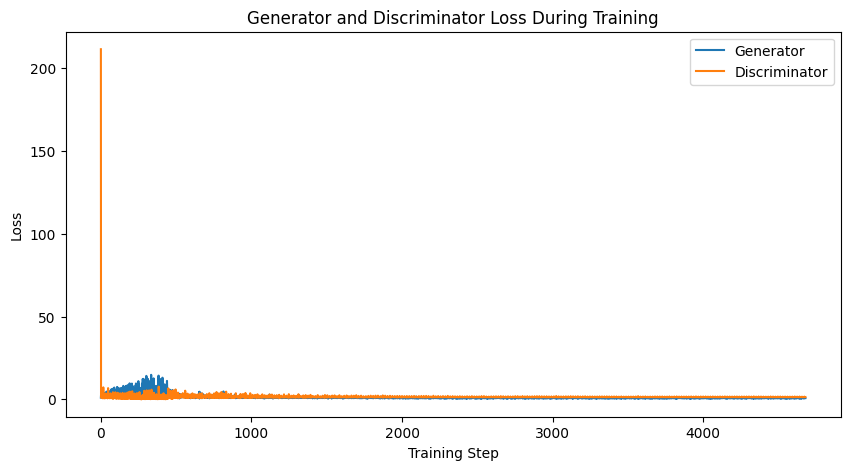

In [17]:
plt.figure(figsize=(10, 5))
plt.title('Generator and Discriminator Loss During Training')
plt.plot(g_losses, label='Generator')
plt.plot(d_losses, label='Discriminator')
plt.xlabel('Training Step')
plt.ylabel('Loss')
plt.legend()
plt.show()

## 8. What DCGAN Could Never Do: StyleGAN's Signature Capabilities

Now that training is complete, let's exercise the things a style-based generator uniquely gives us.

### 8.1 Truncation Trick

Regions of `W`-space far from the average `w` correspond to rarer combinations of attributes in the training data, and the generator is typically less reliable there (lower quality but higher diversity). The **truncation trick** interpolates every sampled `w` toward the dataset's average `w_avg` by a factor `psi ∈ [0, 1]`:

$$w' = w_{avg} + \psi \,(w - w_{avg})$$

- `psi = 1.0` → no truncation, full diversity, occasional lower-quality/artifacty faces.
- `psi → 0.0` → all outputs converge toward the single 'average face', high quality but low diversity.
- `psi ≈ 0.5–0.7` is the typical sweet spot used in the paper.

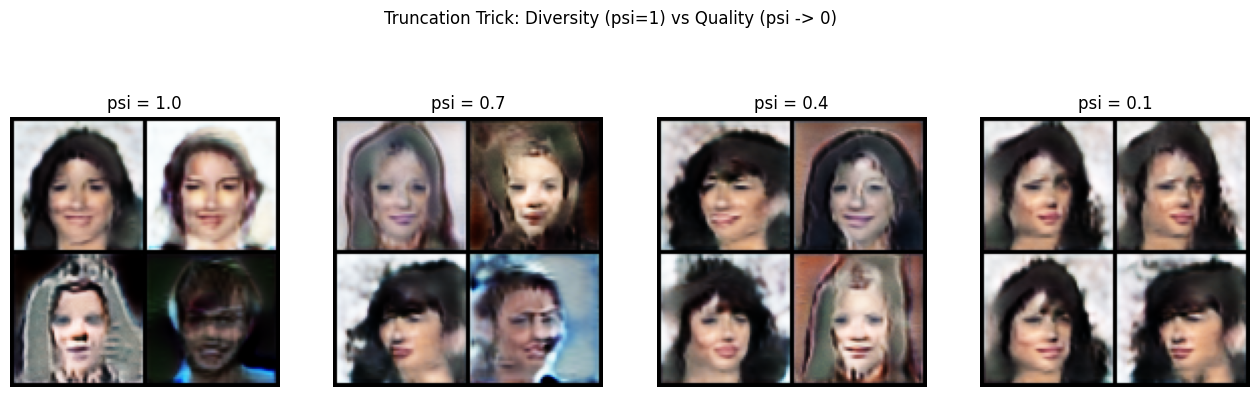

In [18]:
@torch.no_grad()
def get_w_average(mapping_network, z_dim, n_samples=2000):
    z = torch.randn(n_samples, z_dim, device=device)
    w = mapping_network(z)
    return w.mean(dim=0, keepdim=True)

@torch.no_grad()
def generate_with_truncation(psi, n_images=8, w_avg=None):
    generator.eval(); mapping_network.eval()
    if w_avg is None:
        w_avg = get_w_average(mapping_network, Z_DIM)
    z = torch.randn(n_images, Z_DIM, device=device)
    w = mapping_network(z)
    w_truncated = w_avg + psi * (w - w_avg)
    imgs = generator(w_truncated)
    generator.train(); mapping_network.train()
    return imgs

w_avg = get_w_average(mapping_network, Z_DIM)

fig, axes = plt.subplots(1, 4, figsize=(16, 5))
for ax, psi in zip(axes, [1.0, 0.7, 0.4, 0.1]):
    imgs = generate_with_truncation(psi, n_images=4, w_avg=w_avg)
    grid = vutils.make_grid(imgs, nrow=2, normalize=True)
    ax.imshow(np.transpose(grid.cpu(), (1, 2, 0)))
    ax.set_title(f'psi = {psi}')
    ax.axis('off')
plt.suptitle('Truncation Trick: Diversity (psi=1) vs Quality (psi -> 0)')
plt.show()

### 8.2 Style Mixing

Because `w` is injected separately at every synthesis block, we can feed **two different `w` vectors** (from two different source identities) to *different depth ranges* of the generator:
- Using latent A for the early (low-resolution) blocks and latent B for the later (high-resolution) blocks transfers **coarse style** from A (pose, face shape) while keeping **fine style** from B (color, micro-texture).
- Swapping the crossover point changes what gets mixed.

This is the experiment that most convincingly shows `W`-space is doing something DCGAN's `Z`-space cannot.

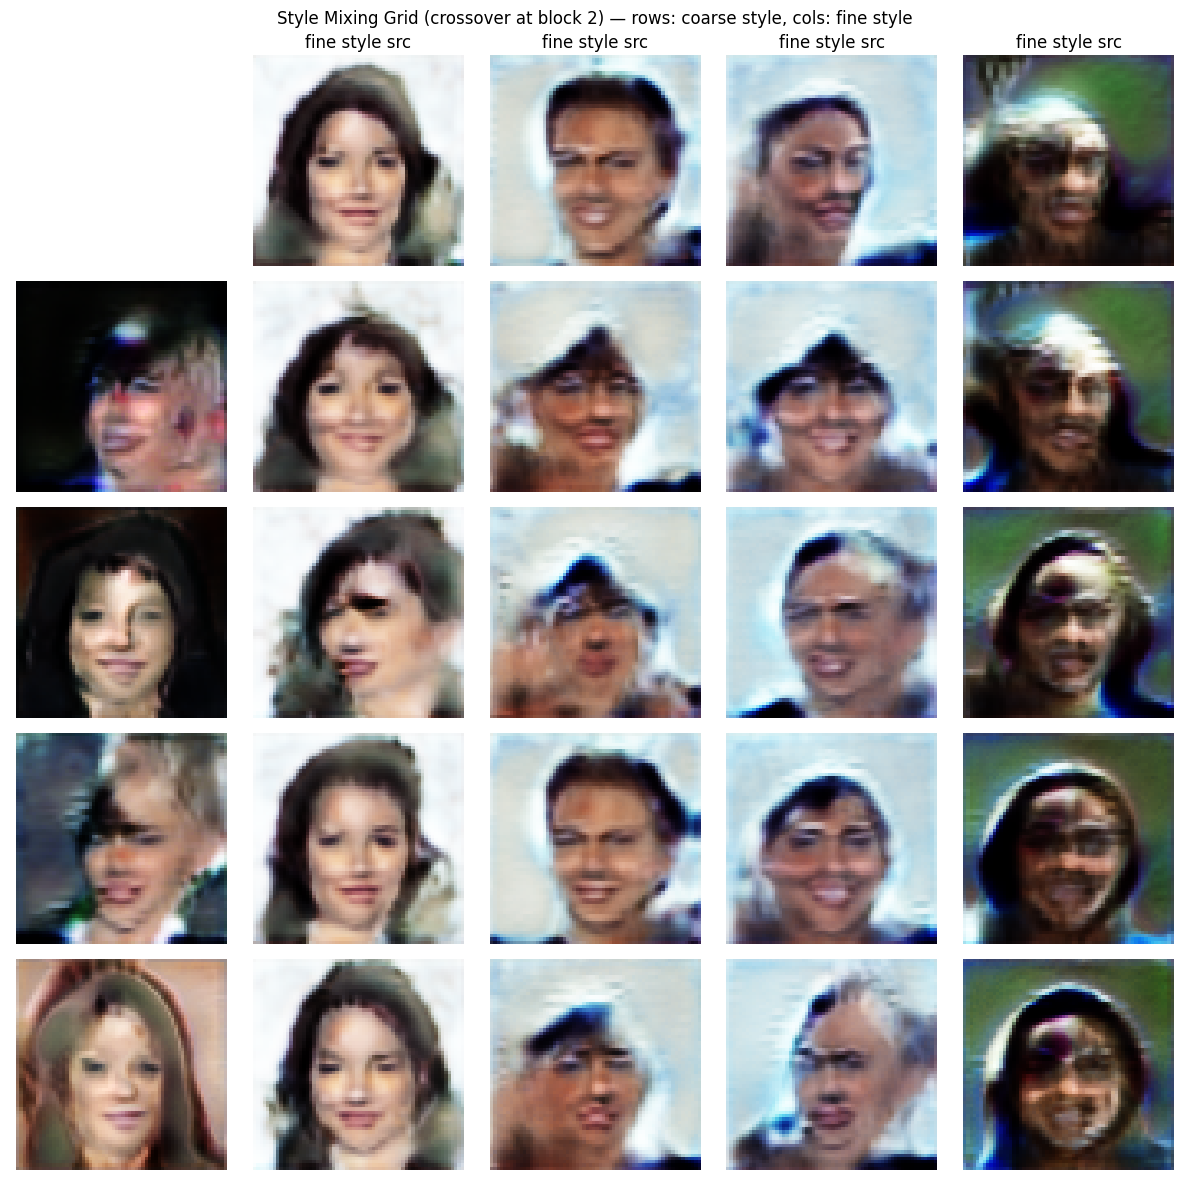

In [19]:
@torch.no_grad()
def style_mix(z_a, z_b, crossover_block):
    """
    Use w_a for blocks [0, crossover_block) and w_b for blocks [crossover_block, end].
    Block index 0 = initial 4x4 constant stage; higher index = higher resolution.
    """
    generator.eval(); mapping_network.eval()
    w_a = mapping_network(z_a)
    w_b = mapping_network(z_b)
    ws = [w_a if i < crossover_block else w_b for i in range(generator.num_style_inputs)]
    img = generator(ws)
    generator.train(); mapping_network.train()
    return img

n_sources = 4
z_sources = torch.randn(n_sources, Z_DIM, device=device)   # define coarse style (rows)
z_targets = torch.randn(n_sources, Z_DIM, device=device)   # define fine style (columns)

fig, axes = plt.subplots(n_sources + 1, n_sources + 1, figsize=(12, 12))

with torch.no_grad():
    w_sources = mapping_network(z_sources)
    w_targets = mapping_network(z_targets)
    imgs_sources = generator(w_sources)
    imgs_targets = generator(w_targets)

axes[0, 0].axis('off')
for i in range(n_sources):
    axes[0, i + 1].imshow(np.transpose(vutils.make_grid(imgs_targets[i], normalize=True).cpu(), (1, 2, 0)))
    axes[0, i + 1].set_title('fine style src'); axes[0, i + 1].axis('off')
    axes[i + 1, 0].imshow(np.transpose(vutils.make_grid(imgs_sources[i], normalize=True).cpu(), (1, 2, 0)))
    axes[i + 1, 0].set_ylabel('coarse style src'); axes[i + 1, 0].axis('off')

CROSSOVER = 2  # try changing this (0..generator.num_style_inputs) to move the mixing point
for i in range(n_sources):
    for j in range(n_sources):
        mixed = style_mix(z_sources[i:i+1], z_targets[j:j+1], crossover_block=CROSSOVER)
        axes[i + 1, j + 1].imshow(np.transpose(vutils.make_grid(mixed, normalize=True).cpu(), (1, 2, 0)))
        axes[i + 1, j + 1].axis('off')

plt.suptitle(f'Style Mixing Grid (crossover at block {CROSSOVER}) — rows: coarse style, cols: fine style')
plt.tight_layout()
plt.show()

### 8.3 Stochastic Variation from Noise (style fixed, noise varied)

Finally, fix `w` (i.e. fix the identity/style) and re-sample only the per-layer noise. You should see the same face with slightly different fine detail (hair strand placement, skin texture) — DCGAN has no equivalent mechanism for this, since its only source of randomness is the single input `z`, which controls identity too.

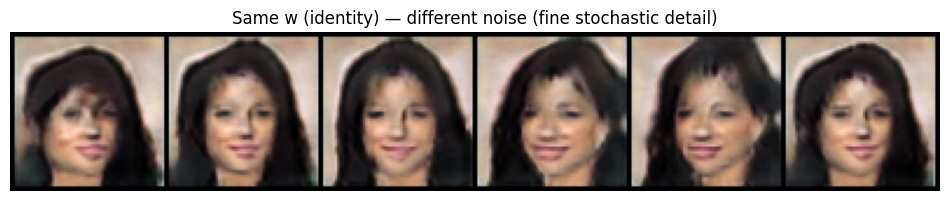

In [20]:
@torch.no_grad()
def show_noise_variation(z_fixed, n_variations=5):
    generator.eval(); mapping_network.eval()
    w = mapping_network(z_fixed)
    w = w.repeat(n_variations, 1)
    imgs = generator(w)  # each forward call re-samples noise internally -> same w, different noise
    generator.train(); mapping_network.train()
    grid = vutils.make_grid(imgs, nrow=n_variations, normalize=True)
    plt.figure(figsize=(12, 3))
    plt.imshow(np.transpose(grid.cpu(), (1, 2, 0)))
    plt.title('Same w (identity) — different noise (fine stochastic detail)')
    plt.axis('off')
    plt.show()

z_fixed = torch.randn(1, Z_DIM, device=device)
show_noise_variation(z_fixed, n_variations=6)

## 9. DCGAN vs. StyleGAN — Summary Comparison

| Aspect | DCGAN (previous lab) | StyleGAN (this lab) |
|---|---|---|
| Latent input | `z` fed once, at the input layer | `z` mapped to `w` (Mapping Network), then `w` injected at **every** layer via AdaIN |
| Style control | None — single entangled vector | Coarse/mid/fine style controllable independently (multiple `w`'s + style mixing) |
| Stochastic detail | Comes only from `z` (entangled with identity) | Dedicated per-layer noise inputs, decoupled from identity |
| Latent space used for editing | `Z` (entangled) | `W` (more disentangled, better for interpolation/editing) |
| Sample diversity vs. quality control | Not adjustable at inference time | Truncation trick lets you trade off at inference time |
| Discriminator | Standard CNN | Standard CNN (same idea — StyleGAN's innovation is generator-side only) |

## 10. Exercises
1. **Resolution:** Extend the `channels` dict and add one more `SynthesisBlock` to reach 128×128. What happens to training time and stability?
2. **Mapping depth:** Reduce `n_layers` in `MappingNetwork` to 2 and compare style-mixing quality against the 6/8-layer version — does disentanglement visibly get worse?
3. **Crossover sweep:** Re-run the style-mixing grid with `CROSSOVER` set to different block indices (0 through `generator.num_style_inputs`). Where does 'coarse' style end and 'fine' style begin, visually?
4. **Quantitative evaluation:** Compute the **Fréchet Inception Distance (FID)** between real and generated samples (e.g. using the `torchmetrics` or `pytorch-fid` packages) and compare it against your DCGAN's FID from the earlier lab.
5. **Progressive growing (advanced):** The original paper trains by progressively growing resolution (start at 4×4, fade in higher-res blocks over time) rather than training at full resolution from step 1. Try implementing a simple fade-in schedule between two resolution stages.
6. **StyleGAN2 (advanced):** Read about StyleGAN2's *weight demodulation*, which replaces AdaIN to remove the 'droplet' artifacts seen in StyleGAN1 outputs. Try swapping AdaIN for weight demodulation in `SynthesisBlock`.

